采样点数： 8000
频点间距： 1.0
峰值频率： 500.0


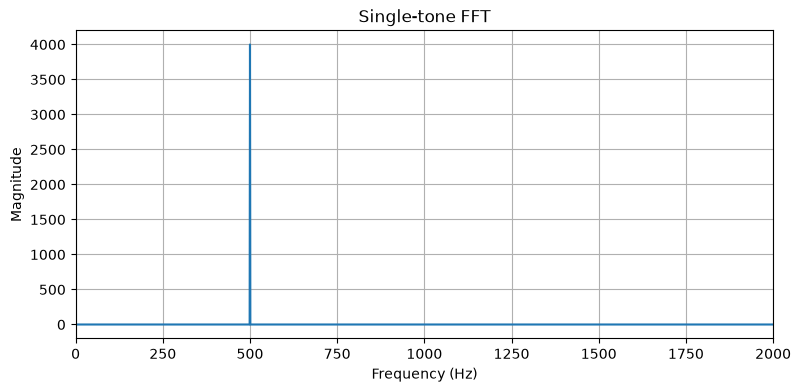

In [3]:
import numpy as np
import matplotlib.pyplot as plt

sr = 8000
duration = 1.0
f = 500

t = np.arange(int(sr*duration)) / sr

#生成单音
s = np.sin(2*np.pi*f*t)

#计算rFFT
fft_s = np.fft.rfft(s)

#频率坐标与幅度谱
freqs = np.fft.rfftfreq(len(s),d=1/sr)
magnitude = np.abs(fft_s)

peak_idx = np.argmax(magnitude)

print("采样点数：",len(s))
print("频点间距：",sr / len(s))
print("峰值频率：",freqs[peak_idx])

#绘制幅度谱
plt.figure(figsize=(9,4))
plt.plot(freqs,magnitude)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("Single-tone FFT")
plt.xlim(0,2000)
plt.grid(True)
plt.show()

主要频率： [ 500. 1500.]
对应幅度谱值： [4000. 2000.]


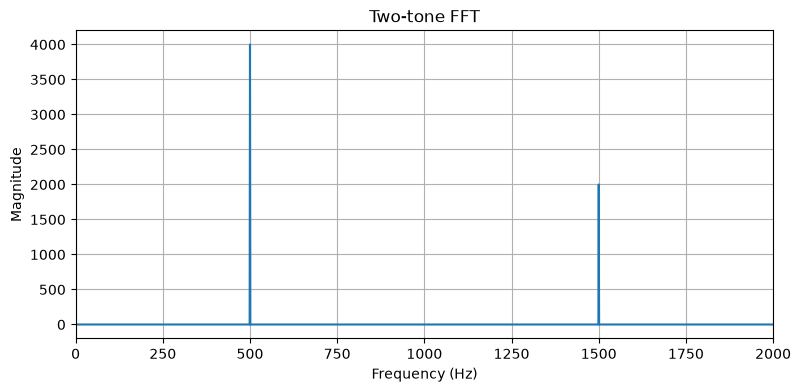

In [7]:
#实验2：两个正弦波叠加
f2 = 1500
s2 = np.sin(2*np.pi*f2*t)

s_mix = s + 0.5 * s2

fft_s_mix = np.fft.rfft(s_mix)
magnitude_mix = np.abs(fft_s_mix)

# 找到幅度最大的两个频点
top2_idx = np.argsort(magnitude_mix)[-2:][::-1]

print("主要频率：",freqs[top2_idx])
print("对应幅度谱值：",magnitude_mix[top2_idx])

plt.figure(figsize=(9,4))
plt.plot(freqs,magnitude_mix)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("Two-tone FFT")
plt.xlim(0,2000)
plt.grid(True)
plt.show()

实际采样点数： 800
补零前频点间距： 10.0
补零后频点间距： 1.0
补零前峰值频率： 440.0
补零后峰值频率： 445.0


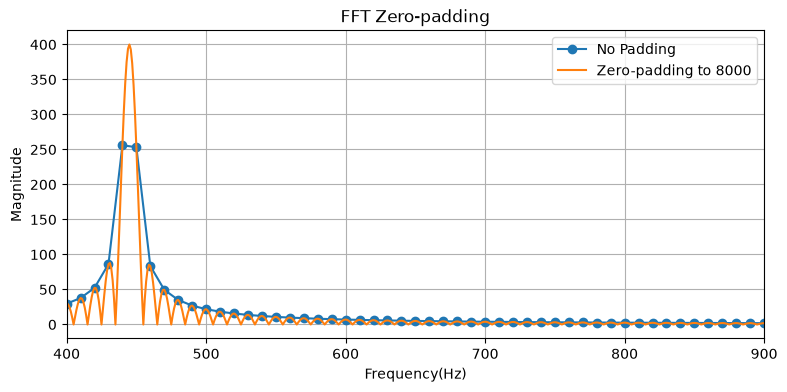

In [8]:
#实验3：FFT补零
sr = 8000
f = 445
duration = 0.1

#只有800个真实采样点
N_obs = int(sr * duration)

t_short = np.arange(N_obs) / sr
x_short = np.sin(2*np.pi*f*t_short)

#情况A:不补零
N_fft1 = N_obs

fft_x1 = np.fft.rfft(x_short,N_fft1)
freqs = np.fft.rfftfreq(N_fft1,d=1/sr)

#情况B:补零到8000
N_fft2 = 8000

fft_x2 = np.fft.rfft(x_short,N_fft2)
freqs2 = np.fft.rfftfreq(N_fft2,d=1/sr)

print("实际采样点数：",N_obs)
print("补零前频点间距：",sr / N_fft1)
print("补零后频点间距：", sr / N_fft2)

print("补零前峰值频率：",freqs[np.argmax(np.abs(fft_x1))])
print("补零后峰值频率：",freqs2[np.argmax(np.abs(fft_x2))])

plt.figure(figsize=(9,4))
plt.plot(freqs,np.abs(fft_x1),"o-",label="No Padding")
plt.plot(freqs2,np.abs(fft_x2),label="Zero-padding to 8000")

plt.xlim(400,900)
plt.xlabel("Frequency(Hz)")
plt.ylabel("Magnitude")
plt.title("FFT Zero-padding")
plt.legend()
plt.grid(True)
plt.show()

采样率： 16000
采样点数： 47616
音频时长： 2.976
频点间距： 0.33602150537634407


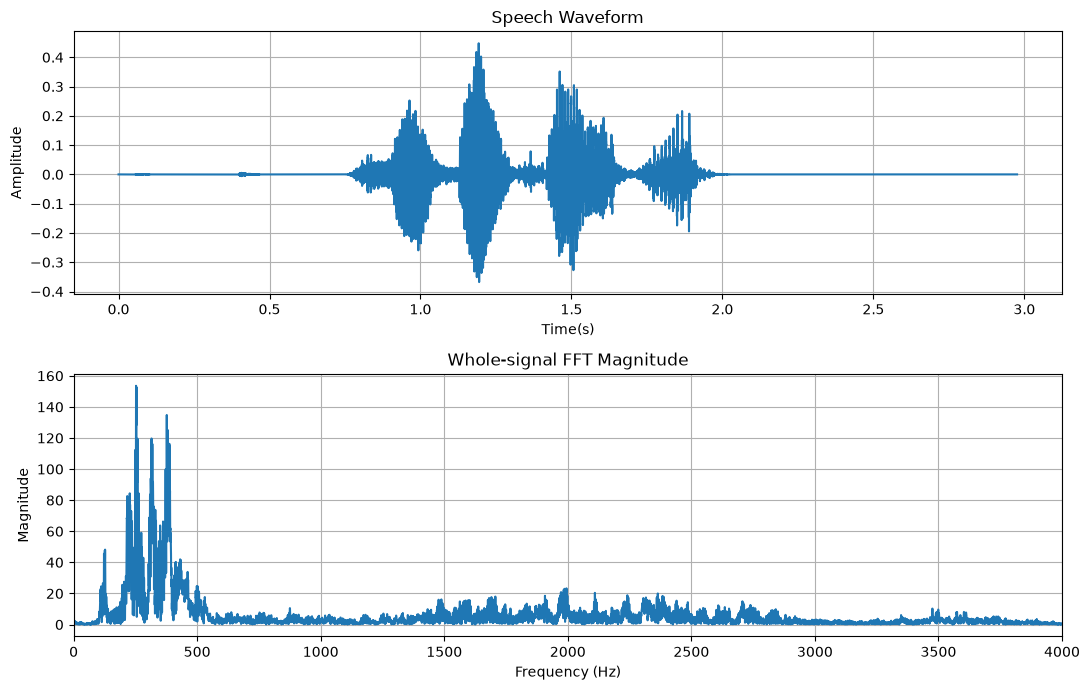

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf
from pathlib import Path


#实验1：观察真实语音的频谱

#根据Notebook运行目录调整路径
audio_path = Path("../data/audio/test_16k.wav")

#soundfile读取(N,C)
audio, sr = sf.read(
    audio_path,
    dtype="float32",
    always_2d=True
)

#转为单声道(T,)
x = audio.mean(axis=1)

N = len(x)
t = np.arange(N) / sr

#整段rFFT
fft_x = np.fft.rfft(x)
freqs = np.fft.rfftfreq(N,d=1/sr)
magnitude = np.abs(fft_x)

print("采样率：",sr)
print("采样点数：",N)
print("音频时长：",N / sr)
print("频点间距：",sr / N)

#绘制时域波形与整段幅度谱
fig, axes = plt.subplots(2,1,figsize=(11,7))

axes[0].plot(t,x)
axes[0].set_xlabel("Time(s)")
axes[0].set_ylabel("Amplitude")
axes[0].set_title("Speech Waveform")
axes[0].grid(True)

axes[1].plot(freqs,magnitude)
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Magnitude")
axes[1].set_title("Whole-signal FFT Magnitude")
axes[1].set_xlim(0, 4000)
axes[1].grid(True)

plt.tight_layout()
plt.show()

幅度谱是否基本相同: True
幅度谱最大差值: 9.094947017729282e-13


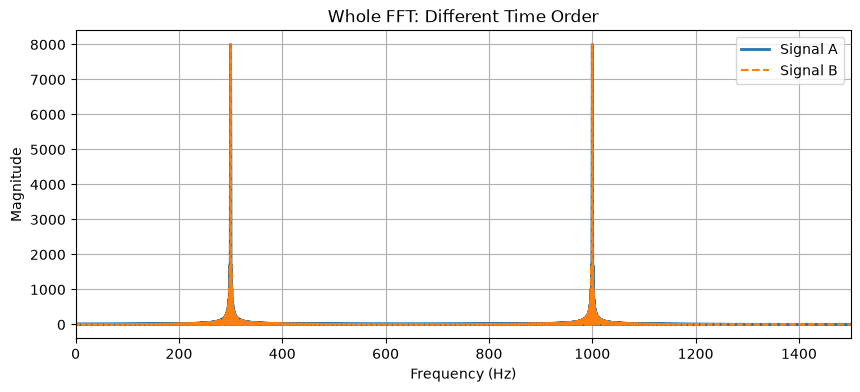

In [11]:
#实验2：改变频率出现的时间，观察整段 FFT
sr = 16000
duration_half = 1.0

t_half = np.arange(int(sr * duration_half)) / sr

#两端不同频率的单音
tone_300 = np.sin(2 * np.pi * 300 * t_half)
tone_1000 = np.sin(2 * np.pi * 1000 * t_half)

#A:先300，再1000
signal_a = np.concatenate([tone_300, tone_1000])

# B：先1000Hz，再300Hz
signal_b = np.concatenate([tone_1000, tone_300])

#对整段2秒信号计算rFFT
x_a = np.fft.rfft(signal_a)
x_b = np.fft.rfft(signal_b)

freqs = np.fft.rfftfreq(len(signal_a), d=1/sr)

mag_a = np.abs(x_a)
mag_b = np.abs(x_b)

print(
    "幅度谱是否基本相同:",
    np.allclose(mag_a, mag_b)
)

print(
    "幅度谱最大差值:",
    np.max(np.abs(mag_a - mag_b))
)

plt.figure(figsize=(10,4))
plt.plot(
    freqs,
    mag_a,
    label="Signal A",
    linewidth=2
)

plt.plot(
    freqs,
    mag_b,
    "--",
    label="Signal B",
    linewidth=1.5
)

plt.xlim(0, 1500)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("Whole FFT: Different Time Order")
plt.legend()
plt.grid(True)

plt.show()

前1秒峰值频率: 300.0
后1秒峰值频率: 1000.0


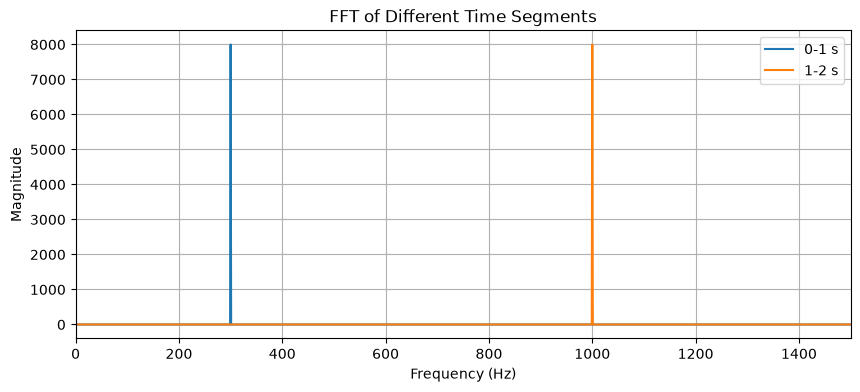

In [13]:
#实验3：如果把音频分成两段再做 FFT 呢？
#分别对两个1s片段计算FFT
first_half = signal_a[:sr]
second_half = signal_a[sr:]

X_first = np.fft.rfft(first_half)
X_second = np.fft.rfft(second_half)

freqs_half = np.fft.rfftfreq(sr, d=1/sr)

peak_first = freqs_half[np.argmax(np.abs(X_first))]
peak_second = freqs_half[np.argmax(np.abs(X_second))]

print("前1秒峰值频率:", peak_first)
print("后1秒峰值频率:", peak_second)

plt.figure(figsize=(10, 4))

plt.plot(
    freqs_half,
    np.abs(X_first),
    label="0-1 s"
)

plt.plot(
    freqs_half,
    np.abs(X_second),
    label="1-2 s"
)

plt.xlim(0, 1500)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("FFT of Different Time Segments")
plt.legend()
plt.grid(True)

plt.show()